# EV Battery SoH Regression: Polynomial vs Tree Regressors (Optuna)

- Target: `SoH_Percent`
- `Battery_Status` and `Vehicle_ID` are dropped
- Outliers are **kept**
- Models: Polynomial Regression (Ridge-regularized), Decision Tree, Random Forest, Extra Trees, Gradient Boosting

Install if needed: `pip install optuna scikit-learn pandas matplotlib seaborn`

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import optuna
from optuna.trial import FixedTrial
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42
N_TRIALS = 40   # per model; raise for better tuning

## 1. Load data

In [2]:
df = pd.read_csv("data/ev_battery_degradation_v1.csv")   # <-- change to your file path
print(df.shape)
df.head()

(10000, 13)


,Vehicle_ID,Car_Model,Battery_Type,Battery_Capacity_kWh,Vehicle_Age_Months,Total_Charging_Cycles,Avg_Temperature_C,Fast_Charge_Ratio,Avg_Discharge_Rate_C,Driving_Style,Internal_Resistance_Ohm,SoH_Percent,Battery_Status
0,1fb46ae8,Tesla Model 3,NMC,75.0,41,390,21.5,0.51,2.22,Aggressive,0.0362,94.60,Healthy
1,b7ef35aa,Tesla Model 3,NMC,75.0,29,401,18.0,0.62,1.34,Aggressive,0.0333,95.68,Healthy
2,76cb49e0,Ford Mustang Mach-E,NMC,88.0,71,941,18.4,0.78,1.48,Conservative,0.0526,89.80,Healthy
3,456a7aef,Ford Mustang Mach-E,NMC,88.0,57,378,10.8,0.61,0.72,Moderate,0.0314,96.29,Healthy
4,bd758049,Tesla Model 3,NMC,75.0,58,239,30.3,0.89,1.48,Conservative,0.0297,96.75,Healthy


## 2. Prepare features (outliers kept)

In [3]:
TARGET = "SoH_Percent"
df = df.drop(columns=["Battery_Status", "Vehicle_ID"])

X = df.drop(columns=[TARGET])
y = df[TARGET]

cat_cols = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print("Categorical:", cat_cols)
print("Numeric:", num_cols)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(X_train.shape, X_test.shape)

Categorical: ['Car_Model', 'Battery_Type', 'Driving_Style']
Numeric: ['Battery_Capacity_kWh', 'Vehicle_Age_Months', 'Total_Charging_Cycles', 'Avg_Temperature_C', 'Fast_Charge_Ratio', 'Avg_Discharge_Rate_C', 'Internal_Resistance_Ohm']
(8000, 10) (2000, 10)


## 3. Quick EDA

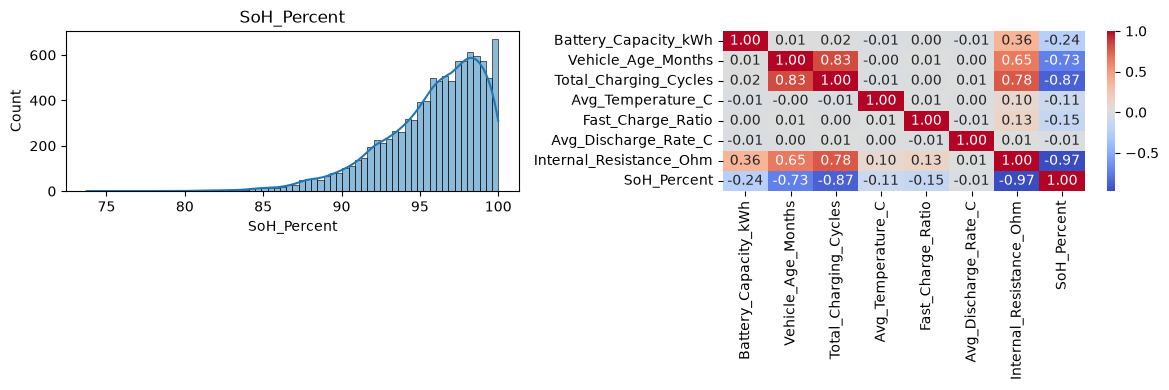

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, kde=True, ax=ax[0]); ax[0].set_title("SoH_Percent")
sns.heatmap(df[num_cols + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1])
plt.tight_layout(); plt.show()

## 4. Preprocessing
- **Polynomial model:** numeric columns are scaled (`RobustScaler`, so outliers don't blow up the higher powers) and expanded with `PolynomialFeatures`; categoricals are one-hot encoded and not expanded.
- **Tree models:** one-hot only, no scaling.

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

def tree_pre():
    return ColumnTransformer([
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])

def poly_pre(degree, interaction_only):
    num_pipe = Pipeline([
        ("scale", RobustScaler()),
        ("poly", PolynomialFeatures(degree=degree, interaction_only=interaction_only, include_bias=False)),
    ])
    return ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])

## 5. Optuna search spaces

In [6]:
def build_model(name, trial):
    if name == "PolynomialRidge":
        degree = trial.suggest_int("degree", 1, 4)
        inter = trial.suggest_categorical("interaction_only", [False, True])
        alpha = trial.suggest_float("alpha", 1e-4, 1e3, log=True)
        return Pipeline([("pre", poly_pre(degree, inter)), ("model", Ridge(alpha=alpha))])

    if name == "DecisionTree":
        m = DecisionTreeRegressor(
            max_depth=trial.suggest_int("max_depth", 3, 30),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 40),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 30),
            max_features=trial.suggest_float("max_features", 0.3, 1.0),
            ccp_alpha=trial.suggest_float("ccp_alpha", 1e-8, 1e-2, log=True),
            random_state=SEED)
    elif name == "RandomForest":
        m = RandomForestRegressor(
            n_estimators=trial.suggest_int("n_estimators", 100, 500),
            max_depth=trial.suggest_int("max_depth", 3, 25),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 20),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
            max_features=trial.suggest_float("max_features", 0.3, 1.0),
            n_jobs=-1, random_state=SEED)
    # elif name == "ExtraTrees":
    #     m = ExtraTreesRegressor(
    #         n_estimators=trial.suggest_int("n_estimators", 100, 500),
    #         max_depth=trial.suggest_int("max_depth", 3, 25),
    #         min_samples_split=trial.suggest_int("min_samples_split", 2, 20),
    #         min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
    #         max_features=trial.suggest_float("max_features", 0.3, 1.0),
    #         n_jobs=-1, random_state=SEED)
    elif name == "GradientBoosting":
        m = GradientBoostingRegressor(
            n_estimators=trial.suggest_int("n_estimators", 100, 600),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            max_depth=trial.suggest_int("max_depth", 2, 8),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 30),
            subsample=trial.suggest_float("subsample", 0.5, 1.0),
            max_features=trial.suggest_float("max_features", 0.3, 1.0),
            random_state=SEED)
    return Pipeline([("pre", tree_pre()), ("model", m)])

model_names = ["PolynomialRidge", "DecisionTree", "RandomForest", "GradientBoosting"]

## 6. Tune each model (5-fold CV RMSE, training set only)

In [14]:
def tune(name, n_trials=N_TRIALS):
    def objective(trial):
        pipe = build_model(name, trial)
        scores = cross_val_score(pipe, X_train, y_train, cv=cv,
                                 scoring="neg_root_mean_squared_error")
        return -scores.mean()
    study = optuna.create_study(direction="minimize",
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    return study

studies = {}
for name in model_names:
    print(f"Tuning {name} ...")
    studies[name] = tune(name)
    print(f"  best CV RMSE: {studies[name].best_value:.4f} | {studies[name].best_params}")

Tuning PolynomialRidge ...
  best CV RMSE: 0.3262 | {'degree': 4, 'interaction_only': False, 'alpha': 10.490588755386023}
Tuning DecisionTree ...
  best CV RMSE: 0.4163 | {'max_depth': 9, 'min_samples_split': 17, 'min_samples_leaf': 7, 'max_features': 0.9475851582616074, 'ccp_alpha': 1.1217049351114992e-08}
Tuning RandomForest ...
  best CV RMSE: 0.3574 | {'n_estimators': 440, 'max_depth': 22, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.9340069913494681}
Tuning GradientBoosting ...
  best CV RMSE: 0.3330 | {'n_estimators': 525, 'learning_rate': 0.018657033543990013, 'max_depth': 5, 'min_samples_leaf': 2, 'subsample': 0.634520284476951, 'max_features': 0.6468030741068758}


## 7. Refit best params and evaluate on the test set

In [15]:
assert len(studies) > 0, "studies is empty - re-run the tuning cell (Section 6) first"

fitted, rows = {}, []
for name, study in studies.items():
    pipe = build_model(name, FixedTrial(study.best_params))
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    rows.append({
        "Model": name,
        "CV_RMSE": study.best_value,
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test_MAE": mean_absolute_error(y_test, pred),
        "Test_R2": r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).sort_values("Test_RMSE").reset_index(drop=True)
results

,Model,CV_RMSE,Test_RMSE,Test_MAE,Test_R2
0,PolynomialRidge,0.326184,0.326753,0.258002,0.989958
1,GradientBoosting,0.332973,0.333718,0.265235,0.989526
2,RandomForest,0.357447,0.372196,0.286738,0.986971
3,DecisionTree,0.416321,0.420445,0.317936,0.983374


In [17]:
import joblib

# 1. Identify the top-performing model name & parameters from Step 7 results
best_model_name = results.loc[0, "Model"]
best_params = studies[best_model_name].best_params

print(f"Exporting Best Model: {best_model_name}")
print(f"Best Parameters: {best_params}")

# 2. Re-build the pipeline and fit on the FULL dataset (X, y) for production
final_pipeline = build_model(best_model_name, FixedTrial(best_params))
final_pipeline.fit(X, y)

# 3. Bundle model pipeline and feature column metadata
export_payload = {
    "model_name": best_model_name,
    "pipeline": final_pipeline,
    "num_cols": num_cols,
    "cat_cols": cat_cols,
    "target": TARGET
}

# 4. Save to disk
model_filepath = "best_ev_battery_soh_pipeline.joblib"
joblib.dump(export_payload, model_filepath)
print(f"Pipeline successfully exported to {model_filepath}")

Exporting Best Model: PolynomialRidge
Best Parameters: {'degree': 4, 'interaction_only': False, 'alpha': 10.490588755386023}
Pipeline successfully exported to best_ev_battery_soh_pipeline.joblib


In [21]:
# Verify loading and predicting using the exported file
loaded_payload = joblib.load("best_ev_battery_soh_pipeline.joblib")
loaded_pipeline = loaded_payload["pipeline"]

# Test prediction on a sample row from test set
sample_input = X_test.iloc[[0]]
sample_pred = loaded_pipeline.predict(sample_input)

print("Sample Input:")
print(sample_input)
print(f"Predicted SoH_Percent: {sample_pred[0]:.2f}")

Sample Input:
          Car_Model Battery_Type  Battery_Capacity_kWh  Vehicle_Age_Months  \
6252  Wuling Air EV          LFP                  26.0                  68   

      Total_Charging_Cycles  Avg_Temperature_C  Fast_Charge_Ratio  \
6252                    432               24.3               0.91   

      Avg_Discharge_Rate_C Driving_Style  Internal_Resistance_Ohm  
6252                  0.61  Conservative                   0.0262  
Predicted SoH_Percent: 96.98


## 8. Best model diagnostics

Best model: PolynomialRidge
Best params: {'degree': 4, 'interaction_only': False, 'alpha': 10.490588755386023}


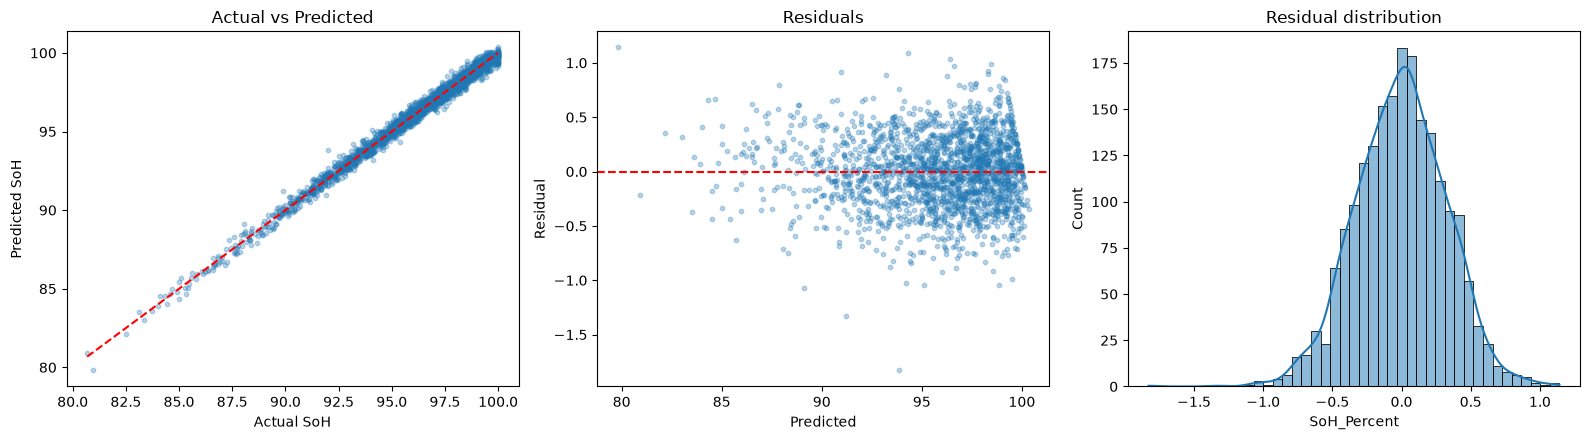

In [18]:
best_name = results.loc[0, "Model"]
best = fitted[best_name]
pred = best.predict(X_test)
print("Best model:", best_name)
print("Best params:", studies[best_name].best_params)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(y_test, pred, alpha=0.3, s=10)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "r--"); ax[0].set_xlabel("Actual SoH"); ax[0].set_ylabel("Predicted SoH"); ax[0].set_title("Actual vs Predicted")
resid = y_test - pred
ax[1].scatter(pred, resid, alpha=0.3, s=10); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Residual"); ax[1].set_title("Residuals")
sns.histplot(resid, kde=True, ax=ax[2]); ax[2].set_title("Residual distribution")
plt.tight_layout(); plt.show()

## 9. Test RMSE comparison

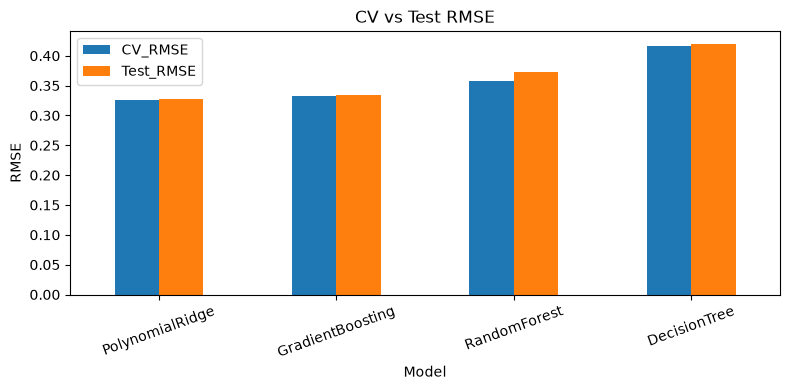

In [19]:
results.set_index("Model")[["CV_RMSE", "Test_RMSE"]].plot(kind="bar", figsize=(8, 4), title="CV vs Test RMSE")
plt.ylabel("RMSE"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## 10. Permutation feature importance (best model)

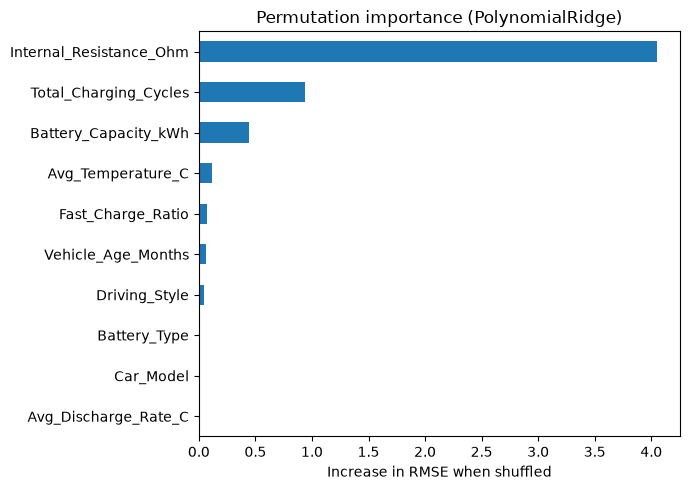

In [20]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(best, X_test, y_test, n_repeats=10, random_state=SEED,
                            scoring="neg_root_mean_squared_error", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.plot(kind="barh", figsize=(7, 5), title=f"Permutation importance ({best_name})")
plt.xlabel("Increase in RMSE when shuffled"); plt.tight_layout(); plt.show()